In [1]:
# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Plotting style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# ==========================================
# STEP 2: LOAD DATASET
# ==========================================

df = pd.read_csv("online_retail.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# ==========================================
# STEP 3: UNDERSTAND THE DATASET
# ==========================================

print("========== FIRST 5 ROWS ==========")
display(df.head())

print("\n========== DATASET SHAPE ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== DATA TYPES & INFORMATION ==========")
df.info()

print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe(include="all").T)

========== FIRST 5 ROWS ==========


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



========== DATASET SHAPE ==========
Rows: 541909
Columns: 8

========== COLUMN NAMES ==========
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

========== DATA TYPES & INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

========== STATISTICAL SUMMARY ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,2011-10-31 14:41:00,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# ==========================================
# STEP 4: CHECK DATA QUALITY
# ==========================================

# Missing values
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
}).sort_values(
    by="Missing Values",
    ascending=False
)

print("========== MISSING VALUES ==========")
display(missing_df)

# Duplicate rows
duplicate_count = df.duplicated().sum()

print("\n========== DUPLICATE RECORDS ==========")
print("Number of duplicate rows:", duplicate_count)

# Basic data types
print("\n========== DATA TYPES ==========")
display(df.dtypes)

========== MISSING VALUES ==========


,Missing Values,Missing Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
InvoiceNo,0,0.000000
StockCode,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000



========== DUPLICATE RECORDS ==========
Number of duplicate rows: 5268

========== DATA TYPES ==========


InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

In [8]:
# ==========================================
# STEP 5: DATA CLEANING
# ==========================================

# Make a copy so original dataset remains safe
df = df.copy()

# Clean column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
before_duplicates = len(df)

df = df.drop_duplicates()

after_duplicates = len(df)

print(
    f"Duplicates removed: "
    f"{before_duplicates - after_duplicates}"
)

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid InvoiceDate
before_date = len(df)

df = df.dropna(
    subset=["InvoiceDate"]
)

print(
    f"Invalid date rows removed: "
    f"{before_date - len(df)}"
)

# Identify cancelled invoices
cancelled_mask = (
    df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

cancelled_count = cancelled_mask.sum()

print(
    f"Cancelled transactions found: "
    f"{cancelled_count}"
)

# Remove cancelled transactions
df = df[
    ~cancelled_mask
].copy()

# Remove invalid quantities
before_quantity = len(df)

df = df[
    df["Quantity"] > 0
].copy()

print(
    f"Invalid quantity rows removed: "
    f"{before_quantity - len(df)}"
)

# Remove invalid prices
before_price = len(df)

df = df[
    df["UnitPrice"] > 0
].copy()

print(
    f"Invalid price rows removed: "
    f"{before_price - len(df)}"
)

# Final dataset information
print("\n========== CLEANING COMPLETED ==========")
print("Final rows:", df.shape[0])
print("Final columns:", df.shape[1])

display(df.head())

Duplicates removed: 5268
Invalid date rows removed: 0
Cancelled transactions found: 9251
Invalid quantity rows removed: 1336
Invalid price rows removed: 1176

========== CLEANING COMPLETED ==========
Final rows: 524878
Final columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
# ==========================================
# STEP 6: FEATURE ENGINEERING
# ==========================================

# Revenue
df["Revenue"] = (
    df["Quantity"] *
    df["UnitPrice"]
)

# Date features
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Month_Name"] = df["InvoiceDate"].dt.month_name()
df["Day"] = df["InvoiceDate"].dt.day
df["Day_Name"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

# Year-Month for time-series analysis
df["Year_Month"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
)

print("Feature engineering completed!")

print("\nNew columns:")
print([
    "Revenue",
    "Year",
    "Month",
    "Month_Name",
    "Day",
    "Day_Name",
    "Hour",
    "Year_Month"
])

display(
    df[
        [
            "InvoiceDate",
            "Quantity",
            "UnitPrice",
            "Revenue",
            "Year",
            "Month",
            "Month_Name",
            "Day_Name",
            "Hour",
            "Year_Month"
        ]
    ].head()
)

Feature engineering completed!

New columns:
['Revenue', 'Year', 'Month', 'Month_Name', 'Day', 'Day_Name', 'Hour', 'Year_Month']


,InvoiceDate,Quantity,UnitPrice,Revenue,Year,Month,Month_Name,Day_Name,Hour,Year_Month
0,2010-12-01 08:26:00,6,2.55,15.30,2010,12,December,Wednesday,8,2010-12
1,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,Wednesday,8,2010-12
2,2010-12-01 08:26:00,8,2.75,22.00,2010,12,December,Wednesday,8,2010-12
3,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,Wednesday,8,2010-12
4,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,Wednesday,8,2010-12


In [10]:
# ==========================================
# STEP 7: FINAL DATA QUALITY CHECK
# ==========================================

print("========== DATASET INFORMATION ==========")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n========== MISSING VALUES ==========")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
)

print("\n========== DUPLICATES ==========")
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print("\n========== REVENUE CHECK ==========")
print(
    "Minimum Revenue:",
    df["Revenue"].min()
)

print(
    "Maximum Revenue:",
    df["Revenue"].max()
)

print(
    "Total Revenue:",
    df["Revenue"].sum()
)

print("\n========== FINAL DATA ==========")
display(df.head())

========== DATASET INFORMATION ==========
Rows: 524878
Columns: 16

========== MISSING VALUES ==========


CustomerID     132186
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
Revenue             0
Year                0
Month               0
Month_Name          0
Day                 0
Day_Name            0
Hour                0
Year_Month          0
dtype: int64


========== DUPLICATES ==========
Duplicate rows: 0

========== REVENUE CHECK ==========
Minimum Revenue: 0.001
Maximum Revenue: 168469.6
Total Revenue: 10642110.804000001

========== FINAL DATA ==========


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_Name,Day,Day_Name,Hour,Year_Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December,1,Wednesday,8,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December,1,Wednesday,8,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,1,Wednesday,8,2010-12


In [11]:
# ==========================================
# STEP 8: BUSINESS KPIs
# ==========================================

# Total Revenue
total_revenue = df["Revenue"].sum()

# Total Units Sold
total_units_sold = df["Quantity"].sum()

# Total Orders
total_orders = df["InvoiceNo"].nunique()

# Unique Products
total_products = df["StockCode"].nunique()

# Unique Customers
total_customers = df["CustomerID"].nunique()

# Countries
total_countries = df["Country"].nunique()

# Average Order Value
average_order_value = (
    total_revenue / total_orders
)

# Average Unit Price
average_unit_price = df["UnitPrice"].mean()

# Average Quantity per Order
average_quantity_per_order = (
    total_units_sold / total_orders
)

# Create KPI table
kpi_df = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Units Sold",
        "Total Orders",
        "Unique Products",
        "Unique Customers",
        "Countries Served",
        "Average Order Value",
        "Average Unit Price",
        "Average Quantity per Order"
    ],

    "Value": [
        f"£{total_revenue:,.2f}",
        f"{total_units_sold:,}",
        f"{total_orders:,}",
        f"{total_products:,}",
        f"{total_customers:,}",
        f"{total_countries:,}",
        f"£{average_order_value:,.2f}",
        f"£{average_unit_price:,.2f}",
        f"{average_quantity_per_order:.2f}"
    ]
})

print("========== BUSINESS KPI SUMMARY ==========")

display(kpi_df)

========== BUSINESS KPI SUMMARY ==========


,KPI,Value
0,Total Revenue,"£10,642,110.80"
1,Total Units Sold,"5,572,420"
2,Total Orders,"19,960"
3,Unique Products,"3,922"
4,Unique Customers,"4,338"
5,Countries Served,38
6,Average Order Value,£533.17
7,Average Unit Price,£3.92
8,Average Quantity per Order,279.18


========== MONTHLY SALES PERFORMANCE ==========


,Year_Month,Revenue,Orders,Units
0,2010-12,821452.730,1559,358019
1,2011-01,689811.610,1086,387099
2,2011-02,522545.560,1100,282934
3,2011-03,716215.260,1454,376599
4,2011-04,536968.491,1246,307953
5,2011-05,769296.610,1681,395001
6,2011-06,760547.010,1533,388511
7,2011-07,718076.121,1475,399693
8,2011-08,757841.380,1361,421020
9,2011-09,1056435.192,1837,569573


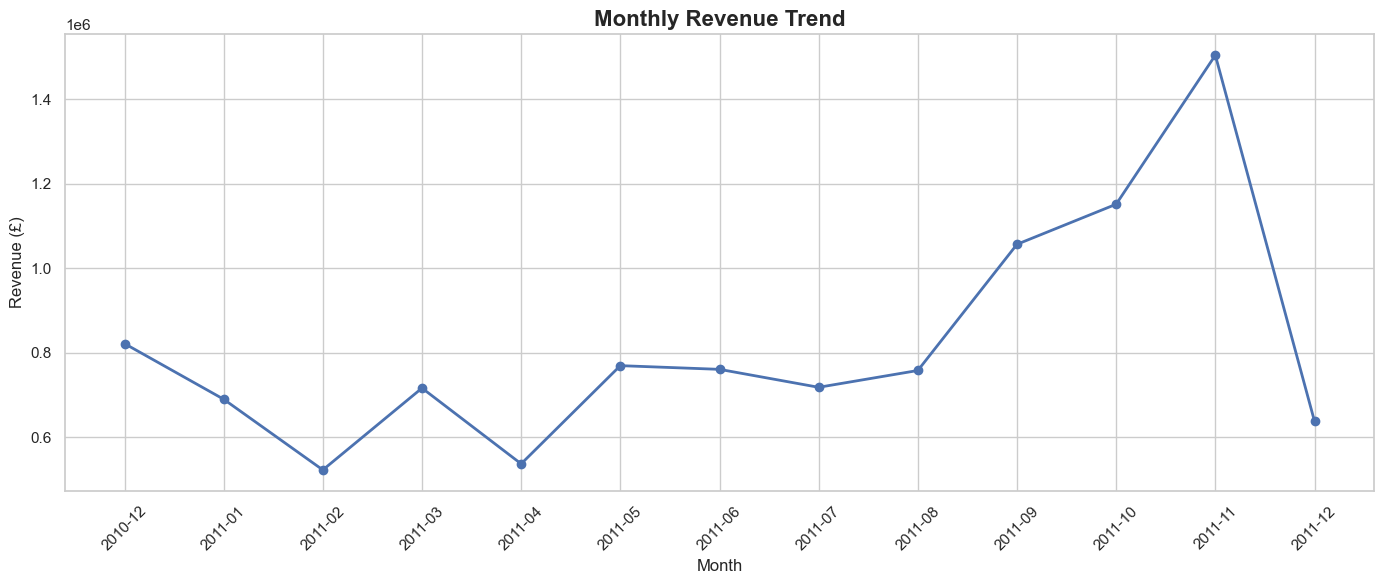

In [12]:
# ==========================================
# STEP 9: REVENUE TREND ANALYSIS
# ==========================================

monthly_revenue = (
    df.groupby("Year_Month")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum")
    )
    .reset_index()
)

# Convert period to string for plotting
monthly_revenue["Year_Month"] = (
    monthly_revenue["Year_Month"]
    .astype(str)
)

print("========== MONTHLY SALES PERFORMANCE ==========")

display(monthly_revenue)

# Plot revenue
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["Year_Month"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Revenue Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

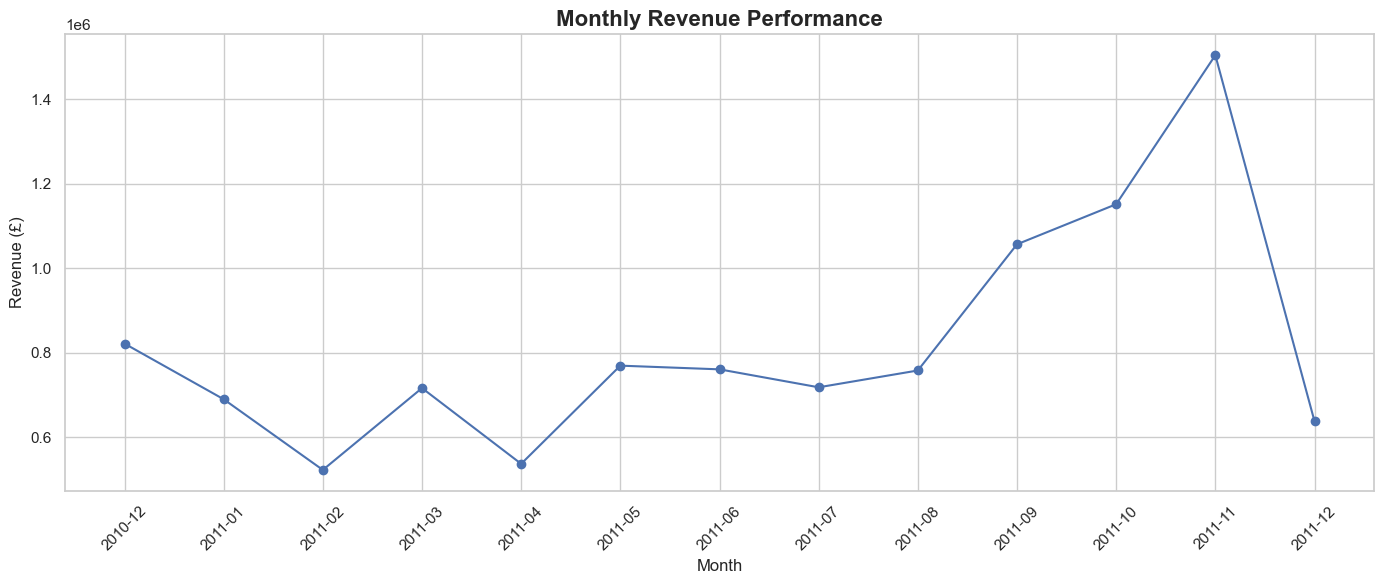

========== MONTHLY ORDERS ==========


,Year_Month,Orders
0,2010-12,1559
1,2011-01,1086
2,2011-02,1100
3,2011-03,1454
4,2011-04,1246
5,2011-05,1681
6,2011-06,1533
7,2011-07,1475
8,2011-08,1361
9,2011-09,1837



========== MONTHLY UNITS ==========


,Year_Month,Units
0,2010-12,358019
1,2011-01,387099
2,2011-02,282934
3,2011-03,376599
4,2011-04,307953
5,2011-05,395001
6,2011-06,388511
7,2011-07,399693
8,2011-08,421020
9,2011-09,569573


In [13]:
# ==========================================
# STEP 10: MONTHLY ORDERS & UNITS
# ==========================================

fig, ax1 = plt.subplots(figsize=(14, 6))

# Revenue
ax1.plot(
    monthly_revenue["Year_Month"],
    monthly_revenue["Revenue"],
    marker="o",
    label="Revenue"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue (£)")

ax1.tick_params(axis="x", rotation=45)

plt.title(
    "Monthly Revenue Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("========== MONTHLY ORDERS ==========")
display(
    monthly_revenue[
        ["Year_Month", "Orders"]
    ]
)

print("\n========== MONTHLY UNITS ==========")
display(
    monthly_revenue[
        ["Year_Month", "Units"]
    ]
)

========== TOP 10 PRODUCTS BY UNITS SOLD ==========


,,Units_Sold,Orders,Revenue
StockCode,Description,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,1,168469.60
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,247,81700.92
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,535,13814.01
85099B,JUMBO BAG RED RETROSPOT,48371,2089,94159.81
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,2189,104284.24
22197,POPCORN HOLDER,36749,803,34288.67
21212,PACK OF 72 RETROSPOT CAKE CASES,36396,1320,21246.45
84879,ASSORTED COLOUR BIRD ORNAMENT,36362,1455,58927.62
23084,RABBIT NIGHT LIGHT,30739,994,66870.03


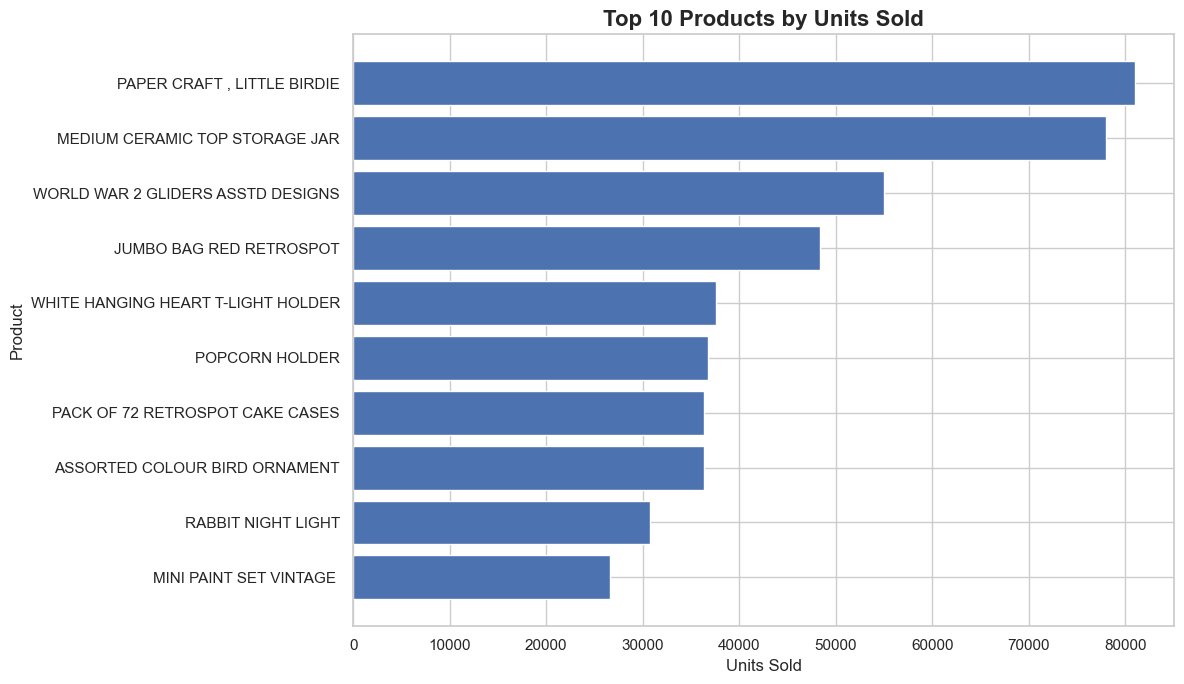

In [14]:
# ==========================================
# STEP 11: TOP-SELLING PRODUCTS
# ==========================================

top_products_quantity = (
    df.groupby(
        ["StockCode", "Description"]
    )
    .agg(
        Units_Sold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Revenue=("Revenue", "sum")
    )
    .sort_values(
        "Units_Sold",
        ascending=False
    )
    .head(10)
)

print("========== TOP 10 PRODUCTS BY UNITS SOLD ==========")

display(top_products_quantity)

# Visualization
plt.figure(figsize=(12, 7))

plot_data = (
    top_products_quantity
    .sort_values("Units_Sold")
)

plt.barh(
    plot_data.index.get_level_values("Description"),
    plot_data["Units_Sold"]
)

plt.title(
    "Top 10 Products by Units Sold",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Units Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

========== TOP 10 PRODUCTS BY REVENUE ==========


,,Revenue,Units_Sold,Orders
StockCode,Description,,,
DOT,DOTCOM POSTAGE,206248.77,706,706
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
47566,PARTY BUNTING,99445.23,18283,1685
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
POST,POSTAGE,78101.88,3150,1126
M,Manual,77750.27,6984,289


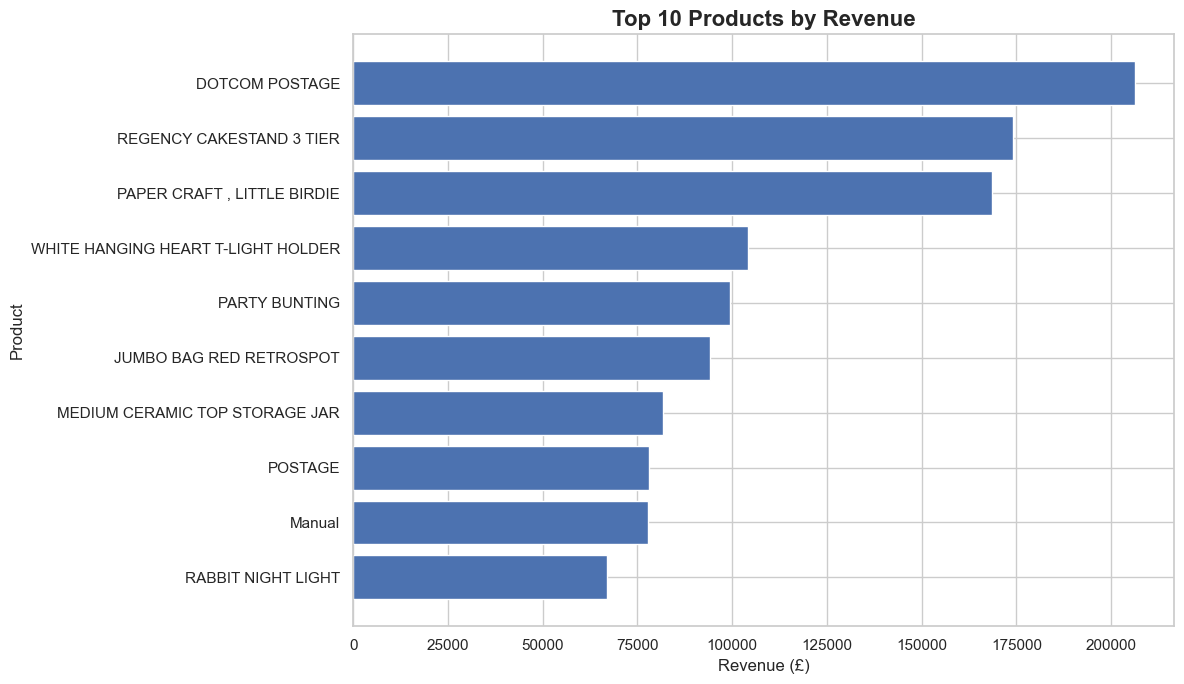

In [15]:
# ==========================================
# STEP 12: TOP PRODUCTS BY REVENUE
# ==========================================

top_revenue_products = (
    df.groupby(
        ["StockCode", "Description"]
    )
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
    .head(10)
)

print("========== TOP 10 PRODUCTS BY REVENUE ==========")

display(top_revenue_products)

# Visualization
plt.figure(figsize=(12, 7))

plot_data = (
    top_revenue_products
    .sort_values("Revenue")
)

plt.barh(
    plot_data.index.get_level_values("Description"),
    plot_data["Revenue"]
)

plt.title(
    "Top 10 Products by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

========== TOP 15 COUNTRIES BY REVENUE ==========


,Revenue,Orders,Units_Sold,Customers
Country,,,,
United Kingdom,9001744.094,18019,4646906,3920
Netherlands,285446.340,94,200361,9
EIRE,283140.520,288,147007,3
Germany,228678.400,457,119154,94
France,209625.370,392,112060,87
Australia,138453.810,57,83891,9
Spain,61558.560,90,27933,30
Switzerland,57067.600,54,30617,21
Belgium,41196.340,98,23237,25


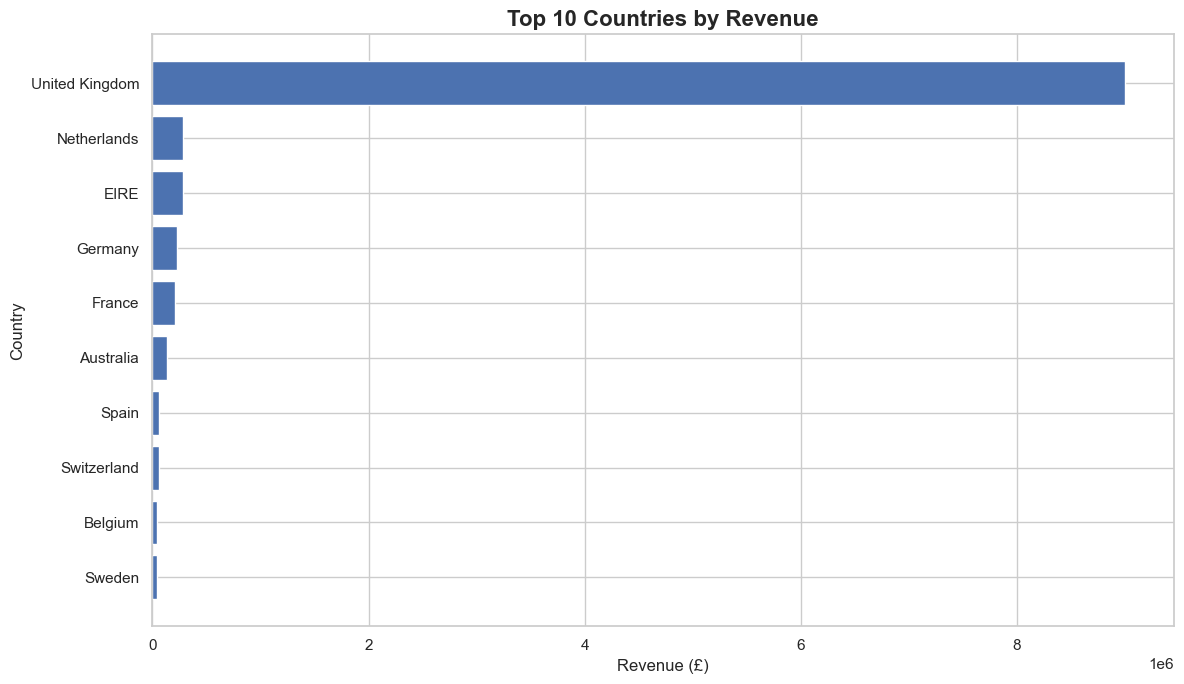

In [16]:
# ==========================================
# STEP 13: REGIONAL PERFORMANCE
# ==========================================

country_performance = (
    df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerID", "nunique")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

print("========== TOP 15 COUNTRIES BY REVENUE ==========")

display(
    country_performance.head(15)
)

# Top 10 countries
top_countries = (
    country_performance
    .head(10)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_countries.index[::-1],
    top_countries["Revenue"][::-1]
)

plt.title(
    "Top 10 Countries by Revenue",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

========== COUNTRY REVENUE CONTRIBUTION ==========


,Revenue,Orders,Units_Sold,Customers,Revenue_%
Country,,,,,
United Kingdom,9001744.094,18019,4646906,3920,84.586078
Netherlands,285446.340,94,200361,9,2.682234
EIRE,283140.520,288,147007,3,2.660567
Germany,228678.400,457,119154,94,2.148807
France,209625.370,392,112060,87,1.969772
Australia,138453.810,57,83891,9,1.301000
Spain,61558.560,90,27933,30,0.578443
Switzerland,57067.600,54,30617,21,0.536243
Belgium,41196.340,98,23237,25,0.387107


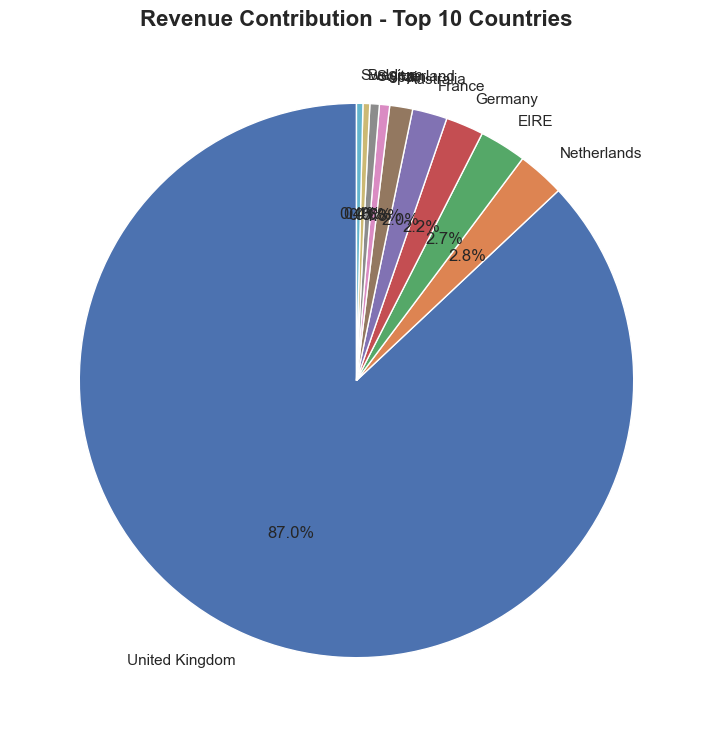

In [17]:
# ==========================================
# STEP 14: REGIONAL REVENUE CONTRIBUTION
# ==========================================

country_performance["Revenue_%"] = (
    country_performance["Revenue"]
    / total_revenue
) * 100

print("========== COUNTRY REVENUE CONTRIBUTION ==========")

display(
    country_performance.head(15)
)

# Pie chart for top 10 countries
top_10 = country_performance.head(10)

plt.figure(figsize=(9, 9))

plt.pie(
    top_10["Revenue"],
    labels=top_10.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    "Revenue Contribution - Top 10 Countries",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [18]:
# ==========================================
# STEP 15: CUSTOMER ANALYSIS
# ==========================================

customer_df = df.dropna(
    subset=["CustomerID"]
).copy()

customer_performance = (
    customer_df.groupby("CustomerID")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum")
    )
    .sort_values(
        "Revenue",
        ascending=False
    )
)

print("========== TOP 10 CUSTOMERS BY REVENUE ==========")

display(
    customer_performance.head(10)
)

print("\n========== TOP 10 CUSTOMERS BY ORDERS ==========")

display(
    customer_performance
    .sort_values("Orders", ascending=False)
    .head(10)
)

========== TOP 10 CUSTOMERS BY REVENUE ==========


,Revenue,Orders,Units
CustomerID,,,
14646.0,280206.02,73,196915
18102.0,259657.30,60,64124
17450.0,194390.79,46,69973
16446.0,168472.50,2,80997
14911.0,143711.17,201,80240
12415.0,124914.53,21,77374
14156.0,117210.08,55,57768
17511.0,91062.38,31,64549
16029.0,80850.84,63,40108



========== TOP 10 CUSTOMERS BY ORDERS ==========


,Revenue,Orders,Units
CustomerID,,,
12748.0,33053.19,209,25287
14911.0,143711.17,201,80240
17841.0,40519.84,124,22834
13089.0,58762.08,97,31025
14606.0,12076.15,93,6187
15311.0,60632.75,91,38147
12971.0,11189.91,86,9289
14646.0,280206.02,73,196915
16029.0,80850.84,63,40108


========== DAY-WISE SALES PERFORMANCE ==========


,Revenue,Orders,Units
Day_Name,,,
Monday,1775782.071,3126.0,871148.0
Tuesday,2175700.511,3554.0,1113087.0
Wednesday,1847074.380,3690.0,1025093.0
Thursday,2199292.570,4246.0,1207384.0
Friday,1837470.491,3140.0,890199.0
Saturday,NaN,NaN,NaN
Sunday,806790.781,2204.0,465509.0


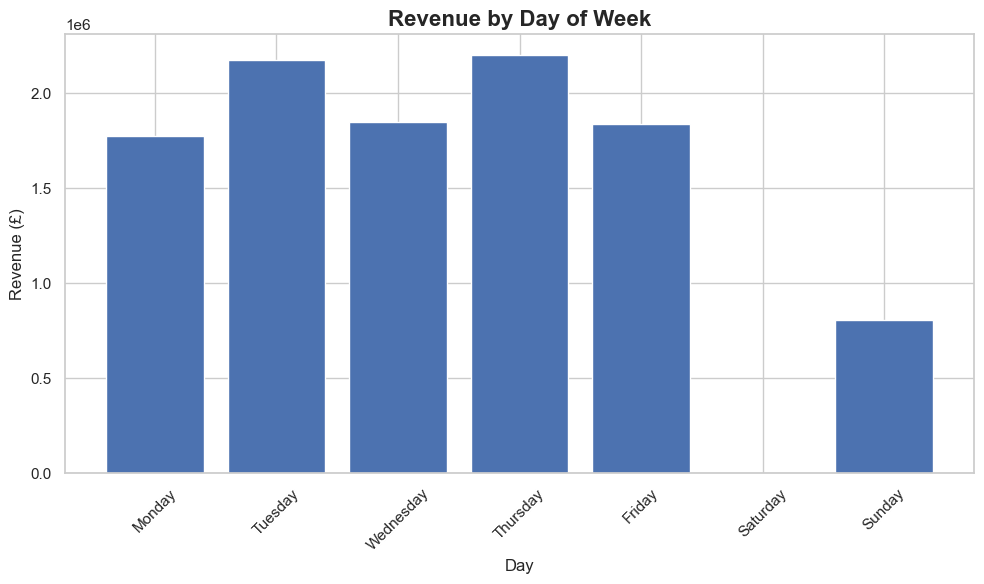

In [19]:
# ==========================================
# STEP 16: DAY-WISE PERFORMANCE
# ==========================================

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_performance = (
    df.groupby("Day_Name")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum")
    )
    .reindex(day_order)
)

print("========== DAY-WISE SALES PERFORMANCE ==========")

display(day_performance)

plt.figure(figsize=(10, 6))

plt.bar(
    day_performance.index,
    day_performance["Revenue"]
)

plt.title(
    "Revenue by Day of Week",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Day")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

========== HOURLY PERFORMANCE ==========


,Revenue,Orders,Units
Hour,,,
6,4.250,1,1
7,31059.210,29,15370
8,283750.680,566,158649
9,990054.991,1484,517985
10,1444814.771,2361,812678
11,1236573.290,2396,671281
12,1439324.660,3220,836642
13,1261195.200,2753,703750
14,1177907.521,2457,597056


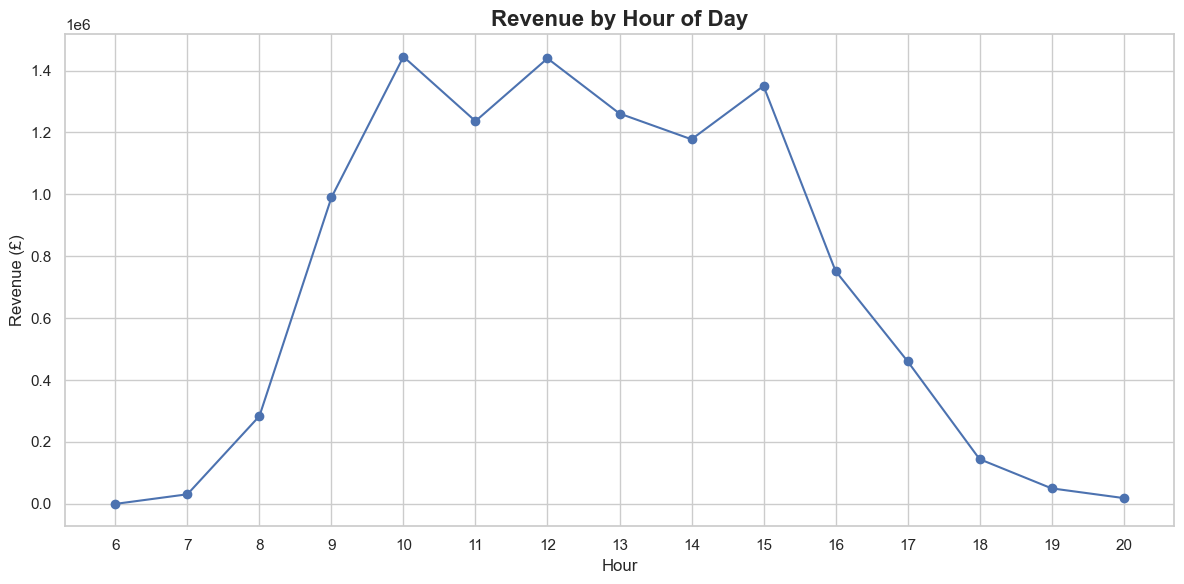

In [20]:
# ==========================================
# STEP 17: HOURLY SALES PERFORMANCE
# ==========================================

hourly_performance = (
    df.groupby("Hour")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum")
    )
)

print("========== HOURLY PERFORMANCE ==========")

display(hourly_performance)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_performance.index,
    hourly_performance["Revenue"],
    marker="o"
)

plt.title(
    "Revenue by Hour of Day",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Hour")
plt.ylabel("Revenue (£)")

plt.xticks(
    range(
        int(df["Hour"].min()),
        int(df["Hour"].max()) + 1
    )
)

plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# STEP 18: HIGH-VALUE PRODUCTS
# ==========================================

product_performance = (
    df.groupby(
        ["StockCode", "Description"]
    )
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
)

# 90th percentile revenue threshold
revenue_threshold = (
    product_performance["Revenue"]
    .quantile(0.90)
)

high_value_products = (
    product_performance[
        product_performance["Revenue"]
        >= revenue_threshold
    ]
    .sort_values(
        "Revenue",
        ascending=False
    )
)

print(
    f"High-value product revenue threshold: "
    f"£{revenue_threshold:,.2f}"
)

print(
    f"Number of high-value products: "
    f"{len(high_value_products)}"
)

display(
    high_value_products.head(20)
)

High-value product revenue threshold: £6,114.24
Number of high-value products: 417


,,Revenue,Units_Sold,Orders
StockCode,Description,,,
DOT,DOTCOM POSTAGE,206248.77,706,706
22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
47566,PARTY BUNTING,99445.23,18283,1685
85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
POST,POSTAGE,78101.88,3150,1126
M,Manual,77750.27,6984,289


========== MONTHLY REVENUE GROWTH ==========


,Year_Month,Revenue,Orders,Units,Revenue_Growth_%
0,2010-12,821452.730,1559,358019,NaN
1,2011-01,689811.610,1086,387099,-16.025404
2,2011-02,522545.560,1100,282934,-24.248077
3,2011-03,716215.260,1454,376599,37.062740
4,2011-04,536968.491,1246,307953,-25.026941
5,2011-05,769296.610,1681,395001,43.266620
6,2011-06,760547.010,1533,388511,-1.137351
7,2011-07,718076.121,1475,399693,-5.584256
8,2011-08,757841.380,1361,421020,5.537750
9,2011-09,1056435.192,1837,569573,39.400568


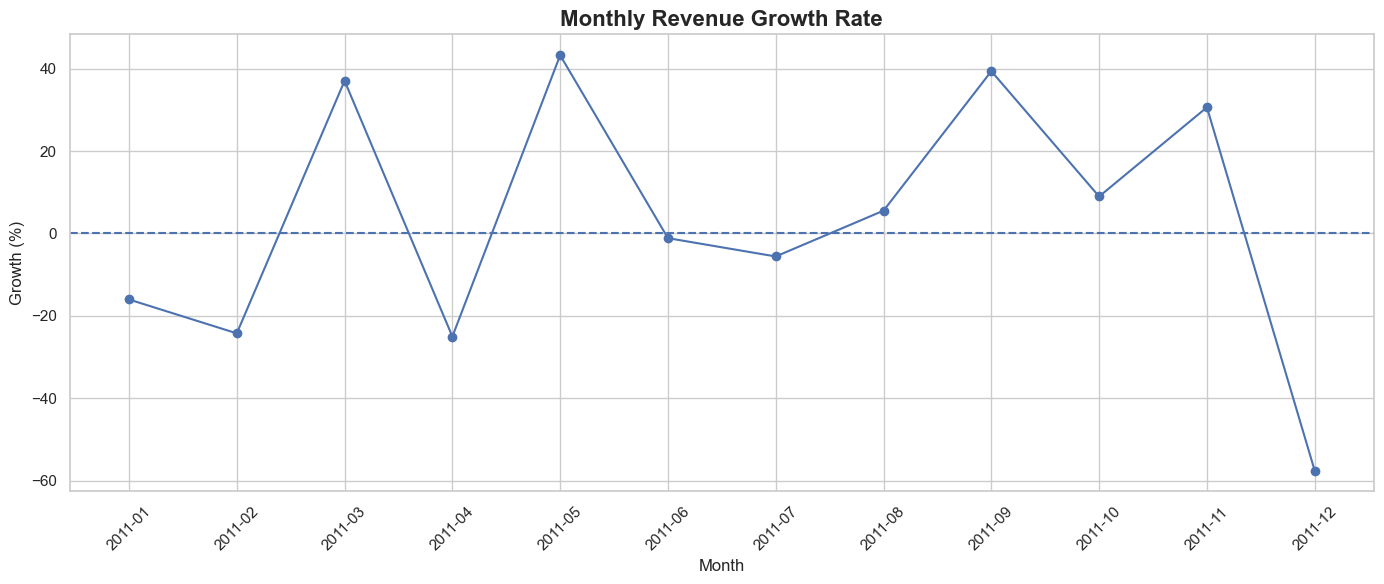

In [22]:
# ==========================================
# STEP 19: REVENUE GROWTH
# ==========================================

monthly_revenue["Revenue_Growth_%"] = (
    monthly_revenue["Revenue"]
    .pct_change()
    * 100
)

print("========== MONTHLY REVENUE GROWTH ==========")

display(monthly_revenue)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["Year_Month"],
    monthly_revenue["Revenue_Growth_%"],
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Monthly Revenue Growth Rate",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# STEP 20: BEST & WORST PERFORMING MONTHS
# ==========================================

best_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmax()
]

worst_month = monthly_revenue.loc[
    monthly_revenue["Revenue"].idxmin()
]

print("========== BEST PERFORMING MONTH ==========")

print(
    "Month:",
    best_month["Year_Month"]
)

print(
    "Revenue:",
    f"£{best_month['Revenue']:,.2f}"
)

print("\n========== WORST PERFORMING MONTH ==========")

print(
    "Month:",
    worst_month["Year_Month"]
)

print(
    "Revenue:",
    f"£{worst_month['Revenue']:,.2f}"
)

========== BEST PERFORMING MONTH ==========
Month: 2011-11
Revenue: £1,503,866.78

========== WORST PERFORMING MONTH ==========
Month: 2011-02
Revenue: £522,545.56


In [24]:
# ==========================================
# STEP 21: BUSINESS SUMMARY
# ==========================================

print("=" * 60)
print("       BUSINESS SALES PERFORMANCE SUMMARY")
print("=" * 60)

print(
    f"\n1. Total Revenue: "
    f"£{total_revenue:,.2f}"
)

print(
    f"2. Total Units Sold: "
    f"{total_units_sold:,}"
)

print(
    f"3. Total Orders: "
    f"{total_orders:,}"
)

print(
    f"4. Unique Products: "
    f"{total_products:,}"
)

print(
    f"5. Unique Customers: "
    f"{total_customers:,}"
)

print(
    f"6. Countries Served: "
    f"{total_countries:,}"
)

print(
    f"7. Average Order Value: "
    f"£{average_order_value:,.2f}"
)

print(
    f"8. Best Revenue Month: "
    f"{best_month['Year_Month']}"
)

print(
    f"9. Best Month Revenue: "
    f"£{best_month['Revenue']:,.2f}"
)

print(
    f"10. Top Revenue Country: "
    f"{country_performance.index[0]}"
)

print(
    f"11. Top Country Revenue: "
    f"£{country_performance.iloc[0]['Revenue']:,.2f}"
)

print(
    f"12. Top Revenue Product: "
    f"{top_revenue_products.index[0][1]}"
)

print(
    f"13. Top Product Revenue: "
    f"£{top_revenue_products.iloc[0]['Revenue']:,.2f}"
)

print("=" * 60)

       BUSINESS SALES PERFORMANCE SUMMARY

1. Total Revenue: £10,642,110.80
2. Total Units Sold: 5,572,420
3. Total Orders: 19,960
4. Unique Products: 3,922
5. Unique Customers: 4,338
6. Countries Served: 38
7. Average Order Value: £533.17
8. Best Revenue Month: 2011-11
9. Best Month Revenue: £1,503,866.78
10. Top Revenue Country: United Kingdom
11. Top Country Revenue: £9,001,744.09
12. Top Revenue Product: DOTCOM POSTAGE
13. Top Product Revenue: £206,248.77


# Business Insights

Based on the analysis, the following business insights were identified:

### Revenue Trends
- Revenue performance varies across different months.
- The highest revenue month indicates the strongest sales period.
- Monthly growth rates help identify periods of growth and decline.

### Product Performance
- A small group of products contributes significantly to total revenue.
- Top-selling products should be monitored for inventory availability.
- High-revenue products can be prioritized for promotions.

### Regional Performance
- Some countries contribute significantly more revenue than others.
- High-performing regions represent important markets.
- Lower-performing regions may require targeted marketing strategies.

### Customer Performance
- A small number of customers may contribute a significant share of revenue.
- High-value customers can be targeted with loyalty and retention strategies.

### Business KPIs
- Total revenue, orders, units sold and Average Order Value provide an overall view of business performance.

# Actionable Business Recommendations

### 1. Focus on High-Revenue Products
Prioritize high-revenue products in inventory planning, promotions and
marketing campaigns.

### 2. Optimize Inventory
Ensure that high-demand products remain available to reduce potential
lost sales caused by stock shortages.

### 3. Target High-Value Customers
Develop loyalty programs and personalized offers for customers who
generate significant revenue.

### 4. Improve Regional Marketing
Focus marketing efforts on high-performing regions while testing
targeted campaigns in lower-performing markets.

### 5. Plan for Seasonal Demand
Use monthly revenue trends to prepare inventory and marketing campaigns
before high-demand periods.

### 6. Increase Average Order Value
Use bundles, cross-selling and product recommendations to encourage
customers to purchase more items per order.

### 7. Monitor Revenue Growth
Track monthly revenue growth regularly to identify declining periods
and respond quickly.

# Conclusion

The Online Retail dataset was analyzed to understand overall business
sales performance.

The analysis covered:

- Revenue trends
- Sales KPIs
- Top-selling products
- High-value products
- Regional performance
- Customer performance
- Daily and hourly sales patterns

The analysis provides a data-driven understanding of the business and
helps identify opportunities for improving revenue, customer value,
product performance and regional sales.

The findings can support better inventory planning, marketing decisions,
customer retention and sales strategy.